# Lab 4: Train and deploy keyword spotting 

Train a small CNN locally to recognize **yes**, **no**, **unknown speech**, and **noise**. Export a fully int8 TensorFlow Lite model and deploy it to the XIAO ESP32S3 Sense. No cloud service or Edge Impulse SDK is used. Internet is needed once for packages and the public dataset.

Run from this project's directory, using the Python 3.12 environment described in `README.md`. Choose **Run All** after reviewing the dataset download size. This notebook uses `tools/kws_training.py` and the matching C++ frontend in `src/kws_features.cpp`. It trains a new model; no accuracy is promised in advance.

## 1. Reproducible configuration

Restart the kernel before running if TensorFlow has already been imported. Legacy Keras is selected before importing TensorFlow for stable TFLite conversion with the pinned versions. The mini dataset download is about **182 MB**; allow about **1 GB of free disk space** for the archive, extracted WAVs and artifacts. Set `AUTO_DOWNLOAD=False` to use an existing mini Speech Commands directory.

`CAP_PER_CLASS` limits training examples per class; validation and test use up to one quarter of that number. Start with a cap of 1,000 and 25 epochs; increase only after the complete deployment works. Environment overrides support small integration checks; ordinary students can edit these values directly.

In [18]:
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from pathlib import Path
import json, sys, platform, hashlib
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import Audio, display

ROOT = Path.cwd().resolve()
assert (ROOT/'platformio.ini').exists(), 'Start Jupyter from the l4-kws directory'
sys.path.insert(0, str(ROOT/'tools'))
import importlib
import kws_training as kws
kws = importlib.reload(kws)  # Pick up helper edits in an existing Jupyter kernel.
LABELS, FRONTEND, SAMPLE_RATE = kws.LABELS, kws.FRONTEND, kws.SAMPLE_RATE
SEED = 42
CAP_PER_CLASS = int(os.environ.get('KWS_CAP', '1000'))
EPOCHS = int(os.environ.get('KWS_EPOCHS', '25'))
DATA_DIR = Path(os.environ.get('KWS_DATA_DIR', ROOT/'data/mini_speech_commands_v1'))
ARTIFACTS = Path(os.environ.get('KWS_ARTIFACT_DIR', ROOT/'artifacts'))
EXPORT_DIR = Path(os.environ.get('KWS_EXPORT_DIR', ROOT/'src'))
EXTRA_DIR = ROOT/'data/extra'
AUTO_DOWNLOAD = os.environ.get('KWS_AUTO_DOWNLOAD', '1') == '1'
assert CAP_PER_CLASS > 0 and EPOCHS > 0
ARTIFACTS.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
print('Python:', platform.python_version(), 'TensorFlow:', tf.__version__)
print('Labels in model order:', LABELS)
print('Data:', DATA_DIR, '\nArtifacts:', ARTIFACTS, '\nFirmware headers:', EXPORT_DIR)

Python: 3.12.11 TensorFlow: 2.19.1
Labels in model order: ('yes', 'no', 'unknown', 'noise')
Data: /Users/heechul/Projects/EmbeddedML/l4-kws/data/mini_speech_commands_v1 
Artifacts: /Users/heechul/Projects/EmbeddedML/l4-kws/artifacts 
Firmware headers: /Users/heechul/Projects/EmbeddedML/l4-kws/src


## 2. Download and split the recordings

Use the [mini Speech Commands dataset](https://www.tensorflow.org/tutorials/audio/simple_audio): 8,000 recordings across eight words, derived from Pete Warden's Speech Commands dataset (CC BY 4.0). Preserve its license and attribution. Keep `yes` and `no`; map `down`, `go`, `left`, `right`, `stop`, and `up` to `unknown`. Mini has no official split lists: a seeded SHA-1 hash of the speaker ID before `_nohash_` assigns approximately 80% of speakers to training, 10% to validation, and 10% to test. All clips from a speaker stay together. We balance the four classes after splitting, so counts vary with the available yes/no recordings.

Mini has **no background-noise recordings**. To retain the four-class lab without downloading the full dataset, the helper generates independent white noise, brown noise, mains hum, and silence examples for each split. Training speech is mixed with generated noise. Synthetic noise does not establish real-room rejection accuracy; supplement it with your own `noise` recordings and test in real environments. If you optionally provide at least three WAV files in `DATA_DIR/_background_noise_`, entire files are assigned to separate splits before cropping instead.

Optional own recordings go in `data/extra/{train,validation,test}/{yes,no,unknown,noise}/<speaker>_nohash_<take>.wav`. Use mono, signed 16-bit PCM at 16 kHz and one-second clips. Keep each speaker in one split, even across labels; the loader audits this. Use separate recording sessions for noise too. Extra recordings enter the capped pools, so raise the cap if needed.

The default `data/mini_speech_commands_v1` is a fresh destination to avoid reusing a mislabeled full dataset. The loader rejects additional word directories or more than 1,000 clips in any word folder. A directory name alone does not verify the dataset.

The download cell reloads `tools/kws_training.py` even in an existing kernel and displays the exact archive URL. It only requests `mini_speech_commands.zip` (~182 MB), checks its SHA-256, and validates all eight folders. It does not request the full Speech Commands TAR archive.

Download URL: https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip

In [19]:
# Reload here too: rerunning only this cell must not use a cached old downloader.
import importlib
import kws_training as kws
kws = importlib.reload(kws)
print('Training helper:', Path(kws.__file__).resolve())
print('Dataset URL:', kws.MINI_DATASET_URL)
print('Archive SHA256:', kws.MINI_SHA256)
if AUTO_DOWNLOAD:
    kws.download_dataset(DATA_DIR)  # Always checks existing data and archive identity.
else:
    kws.validate_mini_dataset(DATA_DIR)
records, noise_sources = kws.split_records(DATA_DIR, cap=CAP_PER_CLASS, seed=SEED, extra=EXTRA_DIR)
for split in records:
    print(split, {label: len(paths) for label, paths in records[split].items()})
    print('  noise:', [p.name for p in noise_sources[split]] or 'generated white/brown/hum + silence')

Training helper: /Users/heechul/Projects/EmbeddedML/l4-kws/tools/kws_training.py
Dataset URL: https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip
Archive SHA256: 49650f2341b26d886b46b3f4fb8fed59e30300b17550f1ee4a768b3106cf93a0
Using verified mini dataset: /Users/heechul/Projects/EmbeddedML/l4-kws/data/mini_speech_commands_v1 (8 words, 1000 WAVs each)
train {'yes': 803, 'no': 803, 'unknown': 803, 'noise': 803}
  noise: generated white/brown/hum + silence
validation {'yes': 91, 'no': 91, 'unknown': 91, 'noise': 91}
  noise: generated white/brown/hum + silence
test {'yes': 98, 'no': 98, 'unknown': 98, 'noise': 98}
  noise: generated white/brown/hum + silence


## 3. Audio → log-mel image

Each example is 16,000 signed int16 samples divided by 32,768. Short speech is padded on the right; longer custom speech is center cropped. A periodic 480-sample Hann window and 320-sample hop give 49 frames; a zero-padded 512-point FFT gives unnormalized power. Apply 32 triangular filters spaced uniformly in HTK mel from 80 to 7,600 Hz. Features are `clip((ln(max(energy, 1e-7)) + 16) / 24, 0, 1)`, in time-major `[49,32,1]` order.

This lab uses **log-mel energies rather than MFCCs** to keep the portable frontend small and inspectable. The model receives features, not raw audio; FFT/log operations run outside TFLite. Do not substitute librosa defaults: window, FFT scaling, mel formula and padding must all agree with firmware.

Training examples receive a zero-filled shift of up to 100 ms, a random gain, and generated noise mixing (or optional recorded backgrounds). This augmentation is sampled **once when the feature arrays are built**, not every epoch. Validation and test speech are unaugmented. Re-run this cell after changing data or the seed.

train (3212, 49, 32, 1) {'yes': 803, 'no': 803, 'unknown': 803, 'noise': 803}
validation (364, 49, 32, 1) {'yes': 91, 'no': 91, 'unknown': 91, 'noise': 91}
test (392, 49, 32, 1) {'yes': 98, 'no': 98, 'unknown': 98, 'noise': 98}


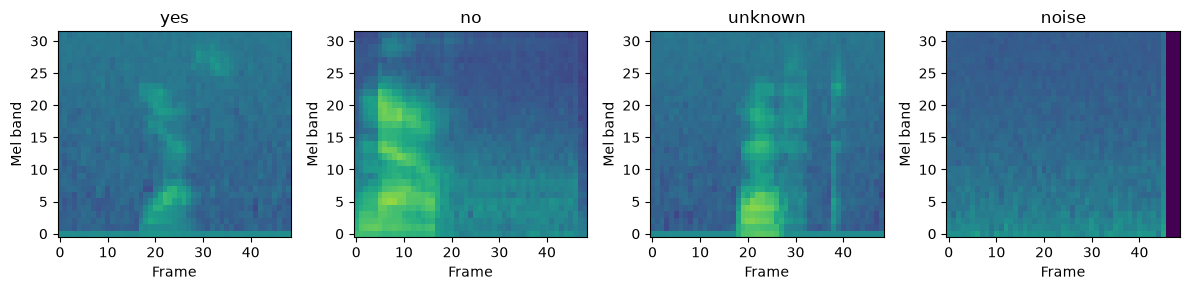

In [20]:
arrays, manifest = kws.make_arrays(records, noise_sources, seed=SEED)
x_train, y_train, pcm_train = arrays['train']
x_val, y_val, pcm_val = arrays['validation']
x_test, y_test, pcm_test = arrays['test']
(ARTIFACTS/'split_manifest.json').write_text(json.dumps(manifest, indent=2))
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for label, ax in enumerate(axes):
    i = np.flatnonzero(y_train == label)[0]
    ax.imshow(x_train[i, :, :, 0].T, origin='lower', aspect='auto', vmin=0, vmax=1)
    ax.set_title(LABELS[label]); ax.set_xlabel('Frame'); ax.set_ylabel('Mel band')
plt.tight_layout()
display(Audio(pcm_train[0], rate=SAMPLE_RATE))

## 4. Train a compact CNN

Two convolution/pooling blocks extract patterns from the 49×32 image. A four-way softmax produces class probabilities. Use validation loss for early stopping and model selection; leave test data untouched until the final evaluation. CPU training is sufficient; runtime depends on the cap and machine.

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 47, 30, 8)         80        
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 23, 15, 8)         0         
 g2D)                                                            
                                                                 
 conv2d_3 (Conv2D)           (None, 21, 13, 16)        1168      
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 10, 6, 16)         0         
 g2D)                                                            
                                                                 
 flatten_1 (Flatten)         (None, 960)               0         
                                                                 
 dropout_1 (Dropout)         (None, 960)              

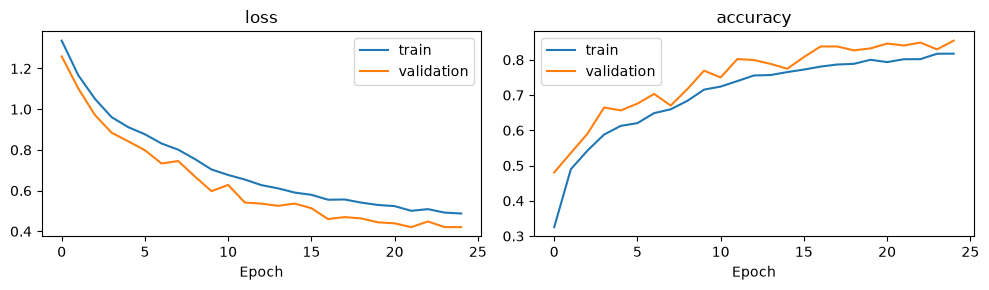

In [21]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(49, 32, 1)),
    tf.keras.layers.Conv2D(8, (3, 3), activation='relu'),
    tf.keras.layers.MaxPool2D((2, 2)),
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu'),
    tf.keras.layers.MaxPool2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(len(LABELS), activation='softmax'),
])
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()
history = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                    batch_size=64, epochs=EPOCHS, shuffle=True,
                    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                                               restore_best_weights=True)])
model.save(str(ARTIFACTS/'kws.keras'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for key in ('loss', 'accuracy'):
    ax = axes[0 if key == 'loss' else 1]
    ax.plot(history.history[key], label='train')
    ax.plot(history.history['val_'+key], label='validation')
    ax.set_title(key); ax.set_xlabel('Epoch'); ax.legend()
plt.tight_layout()

## 5. Convert with representative training features

Full integer quantization needs representative features from **training only**. Limit conversion to int8 built-in operators and require int8 input/output. Save both float and int8 TFLite models. Calibration is unrelated to retraining and must never use the test set.

In [22]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
float_tflite = converter.convert()
calibration_indices = np.random.default_rng(SEED).permutation(len(x_train))[:min(500, len(x_train))]
def representative_data():
    for i in calibration_indices:
        yield [x_train[i:i+1].astype(np.float32)]
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
int8_tflite = converter.convert()
(ARTIFACTS/'kws-float32.tflite').write_bytes(float_tflite)
(ARTIFACTS/'kws-int8.tflite').write_bytes(int8_tflite)
print('Float:', len(float_tflite), 'bytes; int8:', len(int8_tflite), 'bytes')
print('Calibration label counts:', np.bincount(y_train[calibration_indices], minlength=4))

INFO:tensorflow:Assets written to: /var/folders/1d/d9_ykc2515ncj6n85n0v2h0c0000gp/T/tmpr_07_ecn/assets


INFO:tensorflow:Assets written to: /var/folders/1d/d9_ykc2515ncj6n85n0v2h0c0000gp/T/tmpr_07_ecn/assets
W0000 00:00:1793304801.505237 22109783 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793304801.505547 22109783 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.


INFO:tensorflow:Assets written to: /var/folders/1d/d9_ykc2515ncj6n85n0v2h0c0000gp/T/tmp8zh0dps3/assets


INFO:tensorflow:Assets written to: /var/folders/1d/d9_ykc2515ncj6n85n0v2h0c0000gp/T/tmp8zh0dps3/assets
/Users/heechul/Projects/EmbeddedML/l4-kws/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793304801.910013 22109783 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793304801.910022 22109783 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


Float: 23380 bytes; int8: 9248 bytes
Calibration label counts: [114 120 136 130]


## 6. Evaluate and inspect mistakes

The confusion matrix includes **every** held-out example. Report float and int8 accuracy and per-class recall, rather than only confident predictions. Compare quantization loss. The firmware accepts a result only when the best score is ≥0.75 and exceeds the runner-up by ≥0.20; otherwise it reports `uncertain`. These are starting thresholds, not calibrated probabilities. Tune with validation data and real-room trials, then evaluate on test data once after choosing the thresholds.

/Users/heechul/Projects/EmbeddedML/l4-kws/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Validation coverage: 0.6456043956043956
Test float accuracy: 84.949%; int8 accuracy: 84.949%
Accuracy change: +0.00 percentage points
Per-class recall: {'yes': 0.8877551020408163, 'no': 0.8673469387755102, 'unknown': 0.6428571428571429, 'noise': 1.0}
Test coverage: 0.6224489795918368
Accuracy among accepted: 0.9590163934426229
Example error: unknown -> no


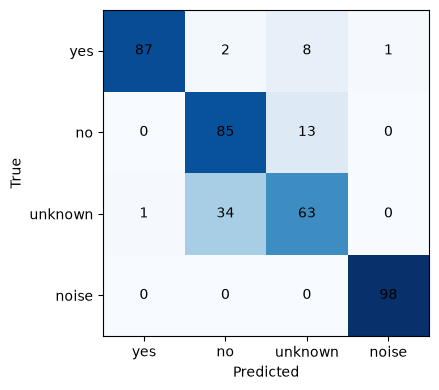

In [23]:
THRESHOLD, MARGIN = 0.75, 0.20  # Match src/main.cpp if changed.
val_scores, _, _ = kws.run_tflite(int8_tflite, x_val)
val_sorted = np.sort(val_scores, axis=1)
val_accept = (val_sorted[:, -1] >= THRESHOLD) & (val_sorted[:, -1]-val_sorted[:, -2] >= MARGIN)
print('Validation coverage:', float(val_accept.mean()))
float_scores, _, _ = kws.run_tflite(float_tflite, x_test)
int8_scores, input_detail, output_detail = kws.run_tflite(int8_tflite, x_test)
float_accuracy = float(np.mean(float_scores.argmax(1) == y_test))
int8_accuracy = float(np.mean(int8_scores.argmax(1) == y_test))
print(f'Test float accuracy: {float_accuracy:.3%}; int8 accuracy: {int8_accuracy:.3%}')
print(f'Accuracy change: {(int8_accuracy-float_accuracy)*100:+.2f} percentage points')
predicted = int8_scores.argmax(1)
confusion = tf.math.confusion_matrix(y_test, predicted, num_classes=4).numpy()
print('Per-class recall:', dict(zip(LABELS, np.diag(confusion)/confusion.sum(1))))
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(confusion, cmap='Blues')
ax.set(xticks=range(4), yticks=range(4), xticklabels=LABELS, yticklabels=LABELS,
       xlabel='Predicted', ylabel='True')
for i in range(4):
    for j in range(4): ax.text(j, i, str(confusion[i,j]), ha='center', va='center')
plt.tight_layout()
sorted_scores = np.sort(int8_scores, axis=1)
accepted = (sorted_scores[:, -1] >= THRESHOLD) & (sorted_scores[:, -1]-sorted_scores[:, -2] >= MARGIN)
print('Test coverage:', float(accepted.mean()))
print('Accuracy among accepted:', float(np.mean(predicted[accepted] == y_test[accepted])) if accepted.any() else 'none accepted')
errors = np.flatnonzero(predicted != y_test)
if len(errors):
    i = errors[0]
    print('Example error:', LABELS[y_test[i]], '->', LABELS[predicted[i]])
    display(Audio(pcm_test[i], rate=SAMPLE_RATE))

## 7. Export firmware headers and a parity fixture

The notebook writes `src/kws_model_data.h` (aligned model bytes and label order) and `src/kws_test_data.h` (a held-out PCM clip, expected int8 features, and desktop TFLite scores). Build and upload **after both headers are generated**. The firmware checks tensor types/shapes, runs the fixture before enabling the microphone, and halts if feature error exceeds one int8 count or score error exceeds 0.03. This detects DSP drift and many runtime/operator incompatibilities; it is not an accuracy test.

If you change the architecture, export rejects operators outside the firmware resolver. Model export does not establish that the MCU has enough tensor-arena memory; check the board's allocation report and self-test.

In [24]:
fixture_index = int(np.flatnonzero(y_test == 0)[0])  # A real held-out "yes" clip.
model_sha = kws.export_headers(int8_tflite, LABELS, pcm_test[fixture_index], EXPORT_DIR)
metadata = dict(dataset='mini_speech_commands', dataset_url=kws.MINI_DATASET_URL,
                dataset_sha256=kws.MINI_SHA256, dataset_counts=kws.validate_mini_dataset(DATA_DIR),
                split_method='seeded SHA1 speaker hash 80/10/10',
                default_noise='synthetic white/brown/hum and silence', labels=LABELS, frontend=FRONTEND, seed=SEED, cap_per_class=CAP_PER_CLASS,
                epochs_requested=EPOCHS, epochs_run=len(history.history['loss']),
                python=platform.python_version(), tensorflow=tf.__version__,
                float_bytes=len(float_tflite), int8_bytes=len(int8_tflite), model_sha256=model_sha,
                float_test_accuracy=float_accuracy, int8_test_accuracy=int8_accuracy,
                threshold=THRESHOLD, margin=MARGIN, test_coverage=float(accepted.mean()),
                confusion_matrix=confusion.tolist(),
                input_quantization=list(input_detail['quantization']),
                output_quantization=list(output_detail['quantization']),
                noise_sources={s: [str(p) for p in paths] for s, paths in noise_sources.items()})
(ARTIFACTS/'metadata.json').write_text(json.dumps(metadata, indent=2))
np.savez(ARTIFACTS/'parity_fixture.npz', pcm=pcm_test[fixture_index],
         features=kws.frontend(pcm_test[fixture_index]))
print('Exported:', EXPORT_DIR/'kws_model_data.h', EXPORT_DIR/'kws_test_data.h')
print('SHA256:', model_sha)
print('Next: pio run -t upload; pio device monitor -b 115200')

/Users/heechul/Projects/EmbeddedML/l4-kws/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Exported: /Users/heechul/Projects/EmbeddedML/l4-kws/src/kws_model_data.h /Users/heechul/Projects/EmbeddedML/l4-kws/src/kws_test_data.h
SHA256: 8e6fb587999db1534a22111afd14a69a331895f221bc461f6c46389c1325f5f5
Next: pio run -t upload; pio device monitor -b 115200


## 8. Optional test on your own recording

Record a one-second mono 16 kHz PCM WAV, put its path below, and run the cell. Keep final assessment recordings out of training and calibration. A laptop microphone and the board microphone have different frequency responses and gain; test both. If transfer is poor, add **training** recordings from the board and re-train, while reserving separate people/sessions for validation and test.

In [25]:
OWN_WAV = ''  # e.g. 'data/my-held-out-yes.wav'
if OWN_WAV:
    own_pcm = kws.one_second(kws.read_pcm(OWN_WAV))
    own_scores, _, _ = kws.run_tflite(int8_tflite, kws.frontend(own_pcm)[None])
    display(Audio(own_pcm, rate=SAMPLE_RATE))
    print(dict(zip(LABELS, own_scores[0].tolist())))

## Lab report

Include the model summary; dataset/split sizes and speaker/noise separation method; training curves; float and int8 sizes and accuracies; confusion matrix and per-class recall; firmware self-test and arena usage; DSP+NN latency; and room trials with yes/no/other words/quiet/background sound. Record false triggers and missed keywords, the distance to the microphone, and the chosen thresholds. Explain the effect of quantization and one experiment changing the dataset, architecture, or thresholds.

References: [TensorFlow audio tutorial](https://www.tensorflow.org/tutorials/audio/simple_audio), [integer quantization](https://www.tensorflow.org/lite/performance/post_training_integer_quant), [XIAO microphone pins and examples](https://wiki.seeedstudio.com/xiao_esp32s3_sense_mic/).